# Итоговый проект: пайплайн подготовки данных для классификации товаров

Цель проекта — подготовить воспроизводимый мультимодальный пайплайн для товаров интернет-магазина. Каждый объект содержит фотографию, текстовое название и метку одного из классов `Handbags`, `Shirts`, `Sports Shoes`, `Watches`.

In [1]:
!wget https://code.s3.yandex.net/thefirstprofession/nod/fashion_project_dataset.zip -O fashion_project_dataset.zip

--2026-10-18 15:49:36--  https://code.s3.yandex.net/thefirstprofession/nod/fashion_project_dataset.zip
Resolving code.s3.yandex.net (code.s3.yandex.net)... 93.158.134.158, 2a02:6b8::2:158
Connecting to code.s3.yandex.net (code.s3.yandex.net)|93.158.134.158|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8975106 (8.6M) [application/zip]
Saving to: ‘fashion_project_dataset.zip’

fashion_project_dat 100%[===================>]   8.56M  --.-KB/s    in 0.1s    

2026-10-18 15:49:37 (57.5 MB/s) - ‘fashion_project_dataset.zip’ saved [8975106/8975106]



In [2]:
!unzip fashion_project_dataset.zip

Archive:  fashion_project_dataset.zip
  inflating: fashion_project_dataset/README.md  
   creating: fashion_project_dataset/images/
  inflating: fashion_project_dataset/metadata.csv  
  inflating: fashion_project_dataset/class_to_idx.csv  
   creating: fashion_project_dataset/images/val/
   creating: fashion_project_dataset/images/test/
   creating: fashion_project_dataset/images/train/
   creating: fashion_project_dataset/images/val/Sports Shoes/
   creating: fashion_project_dataset/images/val/Handbags/
   creating: fashion_project_dataset/images/val/Watches/
   creating: fashion_project_dataset/images/val/Shirts/
  inflating: fashion_project_dataset/images/val/Sports Shoes/4657.jpg  
  inflating: fashion_project_dataset/images/val/Sports Shoes/23842.jpg  
  inflating: fashion_project_dataset/images/val/Sports Shoes/34649.jpg  
  inflating: fashion_project_dataset/images/val/Sports Shoes/4569.jpg  
  inflating: fashion_project_dataset/images/val/Sports Shoes/10037.jpg  
  inflating: f

In [1]:
from collections import Counter
from pathlib import Path
import os
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IMAGE_SIZE = 224
MAX_TEXT_LENGTH = 16
MIN_TOKEN_FREQUENCY = 1
BATCH_SIZE = 32
NUM_WORKERS = 0
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

def find_dataset_root() -> Path:
    configured = os.environ.get('FASHION_DATASET_ROOT')
    candidates = []
    if configured:
        candidates.append(Path(configured).expanduser())
    candidates.extend([
        Path.cwd() / 'fashion_project_dataset',
        Path.cwd() / 'data' / 'fashion_project_dataset',
        Path('/home/froschin/work/masters_degree_Roshchin_M25-555/fashion_project_dataset'),
        Path('/home/froschin/work/masters_degree_Roshchin_M25-555/работа_с_изображениями_и_текстом/3/fashion_project_dataset'),
    ])
    for candidate in candidates:
        if (candidate / 'metadata.csv').is_file() and (candidate / 'class_to_idx.csv').is_file():
            return candidate
    raise FileNotFoundError(
        'Датасет не найден. Укажите путь в переменной FASHION_DATASET_ROOT '
        'или положите папку fashion_project_dataset рядом с ноутбуком.'
    )

DATASET_ROOT = find_dataset_root()
print(f'Корень датасета: {DATASET_ROOT}')
print(f'Устройство для будущего обучения: {"cuda" if torch.cuda.is_available() else "cpu"}')

Корень датасета: /home/froschin/work/masters_degree_Roshchin_M25-555/работа_с_изображениями_и_текстом/3/fashion_project_dataset
Устройство для будущего обучения: cuda


In [5]:
print(torch.cuda.get_device_name())

Tesla V100S-PCIE-32GB


## Этап 1. Аудит и валидация датасета

In [6]:
metadata = pd.read_csv(DATASET_ROOT / 'metadata.csv')
class_to_idx = pd.read_csv(DATASET_ROOT / 'class_to_idx.csv')

required_columns = {'id', 'split', 'class_name', 'label', 'image_path', 'productDisplayName'}
missing_columns = required_columns.difference(metadata.columns)
assert not missing_columns, f'Отсутствуют обязательные колонки: {sorted(missing_columns)}'

print(f'metadata.csv: {metadata.shape[0]:,} строк, {metadata.shape[1]} колонок')
print(f'class_to_idx.csv: {class_to_idx.shape[0]} классов')
print('Колонки metadata:', list(metadata.columns))
display(metadata.head())
display(class_to_idx)

print('Значения split:', sorted(metadata['split'].dropna().unique()))
print('Классы:', sorted(metadata['class_name'].dropna().unique()))
print('Метки:', sorted(metadata['label'].dropna().unique()))
display(pd.crosstab(metadata['split'], metadata['class_name']))
display(pd.crosstab(metadata['split'], metadata['label']))

metadata.csv: 1,200 строк, 14 колонок
class_to_idx.csv: 4 классов
Колонки metadata: ['id', 'split', 'class_name', 'label', 'image_path', 'productDisplayName', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage']


,id,split,class_name,label,image_path,productDisplayName,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage
0,29257,train,Sports Shoes,2,images/train/Sports Shoes/29257.jpg,ADIDAS Men Duramo 4M Grey Sports Shoes,Men,Footwear,Shoes,Sports Shoes,Grey,Summer,2012.0,Sports
1,21481,train,Watches,3,images/train/Watches/21481.jpg,Ice Men XXL White Watch,Men,Accessories,Watches,Watches,White,Winter,2016.0,Casual
2,34637,train,Sports Shoes,2,images/train/Sports Shoes/34637.jpg,Lotto Men Vienna III White Sports Shoes,Men,Footwear,Shoes,Sports Shoes,White,Summer,2012.0,Sports
3,1787,train,Sports Shoes,2,images/train/Sports Shoes/1787.jpg,Lotto Men Court Logo White-Silver Shoe,Men,Footwear,Shoes,Sports Shoes,White,Fall,2010.0,Sports
4,14712,train,Shirts,1,images/train/Shirts/14712.jpg,Genesis Off-White Formal Shirt,Men,Apparel,Topwear,Shirts,Off White,Winter,2011.0,Formal


,class_name,label
0,Handbags,0
1,Shirts,1
2,Sports Shoes,2
3,Watches,3


Значения split: ['test', 'train', 'val']
Классы: ['Handbags', 'Shirts', 'Sports Shoes', 'Watches']
Метки: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


class_name,Handbags,Shirts,Sports Shoes,Watches
split,,,,
test,45,45,45,45
train,210,210,210,210
val,45,45,45,45


label,0,1,2,3
split,,,,
test,45,45,45,45
train,210,210,210,210
val,45,45,45,45


In [7]:
def resolve_image_path(relative_path: str) -> Path:
    path = Path(str(relative_path))
    candidates = [DATASET_ROOT / path, DATASET_ROOT.parent / path, path]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    return DATASET_ROOT / path

metadata['resolved_image_path'] = metadata['image_path'].map(resolve_image_path)
metadata['path_exists'] = metadata['resolved_image_path'].map(Path.is_file)
missing_paths = metadata.loc[~metadata['path_exists'], ['id', 'image_path']]
print(f'Существующих путей: {metadata.path_exists.sum():,}/{len(metadata):,}')
display(missing_paths.head())

image_records = []
broken_images = []
for row in metadata.loc[metadata['path_exists']].itertuples():
    try:
        with Image.open(row.resolved_image_path) as image:
            image.load()
            image_records.append({
                'id': row.id,
                'width': image.width,
                'height': image.height,
                'mode': image.mode,
                'format': image.format,
            })
    except Exception as error:
        broken_images.append({'id': row.id, 'path': str(row.resolved_image_path), 'error': str(error)})

image_info = pd.DataFrame(image_records)
print(f'Повреждённых изображений: {len(broken_images)}')
display(image_info.describe(include='all'))
display(pd.DataFrame(broken_images).head())

Существующих путей: 1,200/1,200


,id,image_path


Повреждённых изображений: 0


,id,width,height,mode,format
count,1200.000000,1200.000000,1200.000000,1200,1200
unique,NaN,NaN,NaN,2,1
top,NaN,NaN,NaN,RGB,JPEG
freq,NaN,NaN,NaN,1184,1200
mean,28197.118333,59.994167,79.983333,NaN,NaN
std,16349.508192,0.202073,0.577350,NaN,NaN
min,1541.000000,53.000000,60.000000,NaN,NaN
25%,12703.000000,60.000000,80.000000,NaN,NaN
50%,27104.500000,60.000000,80.000000,NaN,NaN
75%,42985.250000,60.000000,80.000000,NaN,NaN


""


In [8]:
text_series = metadata['productDisplayName']
metadata['text_missing'] = text_series.isna()
metadata['product_name_clean'] = (
    text_series.fillna('')
    .astype(str)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)
metadata['text_length'] = metadata['product_name_clean'].str.len()
metadata['text_word_count'] = metadata['product_name_clean'].str.split().str.len()

print(f'Пропусков в productDisplayName: {metadata.text_missing.sum()}')
print(f'Пустых названий: {(metadata.text_length == 0).sum()}')
print(f'Названий короче 3 символов: {(metadata.text_length < 3).sum()}')
display(metadata[['text_length', 'text_word_count']].describe().round(2))

label_map = dict(zip(class_to_idx['class_name'], class_to_idx['label']))
metadata['label_from_class'] = metadata['class_name'].map(label_map)
label_consistent = metadata['label'].eq(metadata['label_from_class']).all()
print(f'Соответствие class_name и label: {label_consistent}')
print(f'Дубликатов id: {metadata.id.duplicated().sum()}')
print(f'Дубликатов image_path: {metadata.image_path.duplicated().sum()}')

Пропусков в productDisplayName: 0
Пустых названий: 0
Названий короче 3 символов: 0


,text_length,text_word_count
count,1200.00,1200.00
mean,35.91,6.01
std,8.29,1.31
min,20.00,3.00
25%,30.00,5.00
50%,35.00,6.00
75%,41.00,7.00
max,71.00,11.00


Соответствие class_name и label: True
Дубликатов id: 0
Дубликатов image_path: 0


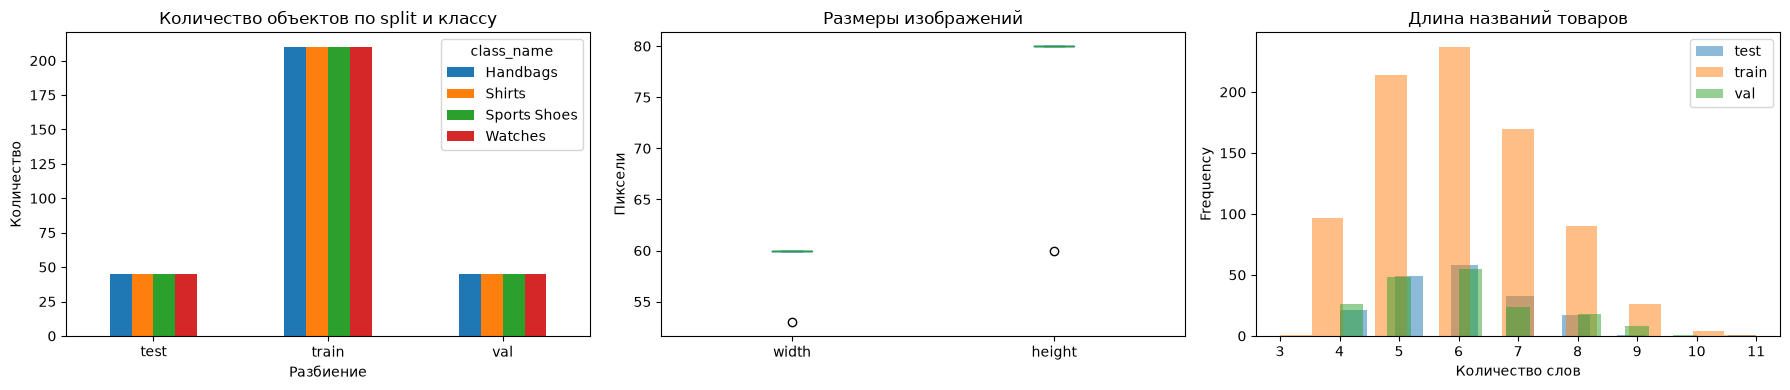

Итог аудита: датасет готов к построению пайплайна.


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
metadata.groupby(['split', 'class_name']).size().unstack(fill_value=0).plot.bar(ax=axes[0])
axes[0].set_title('Количество объектов по split и классу')
axes[0].set_xlabel('Разбиение')
axes[0].set_ylabel('Количество')
axes[0].tick_params(axis='x', rotation=0)
image_info[['width', 'height']].plot(kind='box', ax=axes[1])
axes[1].set_title('Размеры изображений')
axes[1].set_ylabel('Пиксели')
metadata.groupby('split')['text_word_count'].plot(kind='hist', bins=15, alpha=0.5, ax=axes[2], legend=True)
axes[2].set_title('Длина названий товаров')
axes[2].set_xlabel('Количество слов')
plt.tight_layout()
plt.show()

audit_ok = (
    len(missing_paths) == 0
    and len(broken_images) == 0
    and label_consistent
    and metadata['text_length'].gt(0).all()
)
print(f'Итог аудита: {"датасет готов к построению пайплайна" if audit_ok else "обнаружены проблемы, см. таблицы выше"}.')

### Вывод по этапу 1

В датасете 1200 объектов четырёх классов: Handbags, Shirts, Sports Shoes и Watches. Разбиение сбалансировано: в train находится по 210 объектов каждого класса, в validation и test — по 45 объектов каждого класса. Соответствие названий классов числовым меткам подтверждено, дубликатов идентификаторов и путей к изображениям нет.

Все 1200 путей к изображениям существуют, изображения успешно открываются, битых файлов не обнаружено. Файлы имеют формат JPEG и небольшие исходные размеры — примерно 60×80 пикселей. Большинство изображений находятся в режиме RGB, а все изображения дополнительно переводятся в RGB внутри `ProductDataset`, поэтому различия режимов не нарушают обработку. Небольшой размер изображений может ограничивать распознавание мелких визуальных деталей.

Пропусков и пустых названий товаров нет. В среднем название содержит 6,01 слова; длина названий составляет от 3 до 11 слов. Таким образом, текстовые признаки пригодны для токенизации и подачи в модель. В названиях часто встречаются слова, напрямую связанные с полом, цветом и категорией товара, поэтому при дальнейшем обучении нужно проверить, не использует ли мультимодальная модель текстовые подсказки как слишком простой признак класса.

По результатам аудита датасет согласован и готов к построению пайплайна подготовки данных.

## Этап 2. Подготовка изображений

Для train используются случайные аугментации, чтобы модель видела немного разные варианты одного товара. Для val и test применяются только детерминированные операции: Resize, перевод в RGB/тензор и нормализация. Это делает оценку стабильной и не меняет тестовые данные искусственно.

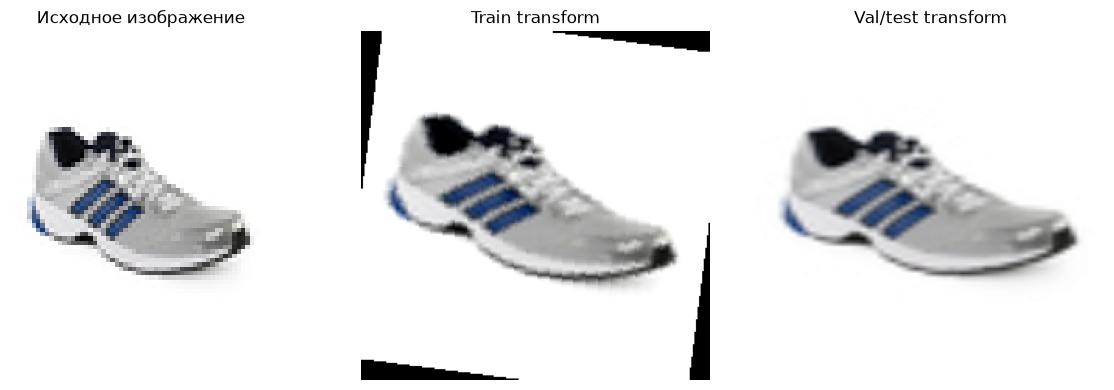

In [11]:
train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

test_transforms = val_transforms

def denormalize(image_tensor):
    image = image_tensor.detach().cpu().clone()
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (image * std + mean).clamp(0, 1)

image_sample_path = metadata.loc[metadata['path_exists'], 'resolved_image_path'].iloc[0]
with Image.open(image_sample_path) as image:
    original_image = image.convert('RGB')

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(original_image)
axes[0].set_title('Исходное изображение')
axes[1].imshow(denormalize(train_transforms(original_image)).permute(1, 2, 0))
axes[1].set_title('Train transform')
axes[2].imshow(denormalize(val_transforms(original_image)).permute(1, 2, 0))
axes[2].set_title('Val/test transform')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
plt.show()

## Этап 3. Подготовка текстовых названий товаров

Очистка текста выполняется одинаково для всех split, но словарь строится только по train. Токены `<PAD>` и `<UNK>` позволяют получить последовательности одинаковой длины и обработать слова, которых не было в обучающей выборке.

In [12]:
TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:['-][a-z0-9]+)?")

def normalize_product_name(value: object) -> str:
    if pd.isna(value):
        return ''
    text = str(value).lower()
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def tokenize_product_name(text: str) -> list[str]:
    return TOKEN_PATTERN.findall(normalize_product_name(text))

metadata['normalized_name'] = metadata['productDisplayName'].map(normalize_product_name)
metadata['tokens'] = metadata['normalized_name'].map(tokenize_product_name)

train_texts = metadata.loc[metadata['split'].eq('train'), 'tokens']
token_counter = Counter(token for tokens in train_texts for token in tokens)
SPECIAL_TOKENS = ['<PAD>', '<UNK>']
vocabulary = SPECIAL_TOKENS + sorted(
    token for token, frequency in token_counter.items()
    if frequency >= MIN_TOKEN_FREQUENCY
)
token_to_idx = {token: index for index, token in enumerate(vocabulary)}
PAD_IDX = token_to_idx['<PAD>']
UNK_IDX = token_to_idx['<UNK>']

def encode_text(text: str, max_length: int = MAX_TEXT_LENGTH) -> torch.Tensor:
    token_ids = [token_to_idx.get(token, UNK_IDX) for token in tokenize_product_name(text)]
    token_ids = token_ids[:max_length]
    token_ids.extend([PAD_IDX] * (max_length - len(token_ids)))
    return torch.tensor(token_ids, dtype=torch.long)

print(f'Размер словаря: {len(vocabulary):,}')
print('Самые частые токены:', token_counter.most_common(15))
for example in metadata.loc[metadata['split'].eq('train'), 'productDisplayName'].head(3):
    print('Исходный текст:', example)
    print('Токены:', tokenize_product_name(example))
    print('Индексы:', encode_text(example).tolist())
    print()

Размер словаря: 764
Самые частые токены: [('men', 432), ('women', 304), ('black', 218), ('white', 194), ('watch', 194), ('shoes', 149), ('shirt', 146), ('sports', 145), ('dial', 142), ('handbag', 134), ('blue', 105), ('check', 69), ('nike', 67), ('grey', 63), ('shirts', 61)]
Исходный текст: ADIDAS Men Duramo 4M Grey Sports Shoes
Токены: ['adidas', 'men', 'duramo', '4m', 'grey', 'sports', 'shoes']
Индексы: [68, 436, 226, 33, 314, 642, 612, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Исходный текст: Ice Men XXL White Watch
Токены: ['ice', 'men', 'xxl', 'white', 'watch']
Индексы: [343, 436, 753, 738, 734, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Исходный текст: Lotto Men Vienna III White Sports Shoes
Токены: ['lotto', 'men', 'vienna', 'iii', 'white', 'sports', 'shoes']
Индексы: [412, 436, 725, 345, 738, 642, 612, 0, 0, 0, 0, 0, 0, 0, 0, 0]



## Этап 4. Собственный PyTorch Dataset

In [13]:
class ProductDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, image_transform, max_text_length: int = MAX_TEXT_LENGTH):
        self.frame = frame.reset_index(drop=True)
        self.image_transform = image_transform
        self.max_text_length = max_text_length

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> dict:
        row = self.frame.iloc[index]
        with Image.open(row['resolved_image_path']) as image:
            image = image.convert('RGB')
            image_tensor = self.image_transform(image)
        return {
            'image': image_tensor,
            'text': encode_text(row['normalized_name'], self.max_text_length),
            'label': torch.tensor(int(row['label']), dtype=torch.long),
            'image_path': str(row['resolved_image_path']),
            'product_name': str(row['productDisplayName']),
            'class_name': str(row['class_name']),
        }

train_frame = metadata[metadata['split'].eq('train')].copy()
val_frame = metadata[metadata['split'].eq('val')].copy()
test_frame = metadata[metadata['split'].eq('test')].copy()

train_dataset = ProductDataset(train_frame, train_transforms)
val_dataset = ProductDataset(val_frame, val_transforms)
test_dataset = ProductDataset(test_frame, test_transforms)

sample_item = train_dataset[0]
print('Размер train_dataset:', len(train_dataset))
print('Тип image:', type(sample_item['image']))
print('Форма image:', tuple(sample_item['image'].shape))
print('Тип text:', type(sample_item['text']))
print('Форма text:', tuple(sample_item['text'].shape))
print('label:', sample_item['label'].item())
print('class_name:', sample_item['class_name'])
print('product_name:', sample_item['product_name'])
assert sample_item['image'].shape == (3, IMAGE_SIZE, IMAGE_SIZE)
assert sample_item['text'].shape == (MAX_TEXT_LENGTH,)

Размер train_dataset: 840
Тип image: <class 'torch.Tensor'>
Форма image: (3, 224, 224)
Тип text: <class 'torch.Tensor'>
Форма text: (16,)
label: 2
class_name: Sports Shoes
product_name: ADIDAS Men Duramo 4M Grey Sports Shoes


## Этап 5. DataLoader и проверка батчей

In [14]:
loader_kwargs = {
    'batch_size': BATCH_SIZE,
    'num_workers': NUM_WORKERS,
    'pin_memory': torch.cuda.is_available(),
}
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

train_batch = next(iter(train_loader))
print('Ключи батча:', list(train_batch.keys()))
print('Форма изображений:', tuple(train_batch['image'].shape))
print('Форма текстов:', tuple(train_batch['text'].shape))
print('Форма меток:', tuple(train_batch['label'].shape))
print('Метки:', train_batch['label'].tolist())

assert train_batch['image'].shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert train_batch['text'].shape[1] == MAX_TEXT_LENGTH
assert train_batch['label'].ndim == 1
print('Батч имеет формы, подходящие для подачи в модель классификации.')

Ключи батча: ['image', 'text', 'label', 'image_path', 'product_name', 'class_name']
Форма изображений: (32, 3, 224, 224)
Форма текстов: (32, 16)
Форма меток: (32,)
Метки: [3, 0, 2, 3, 0, 0, 2, 3, 3, 0, 2, 2, 1, 3, 3, 1, 1, 3, 1, 3, 1, 1, 0, 2, 1, 1, 3, 3, 1, 0, 1, 3]
Батч имеет формы, подходящие для подачи в модель классификации.


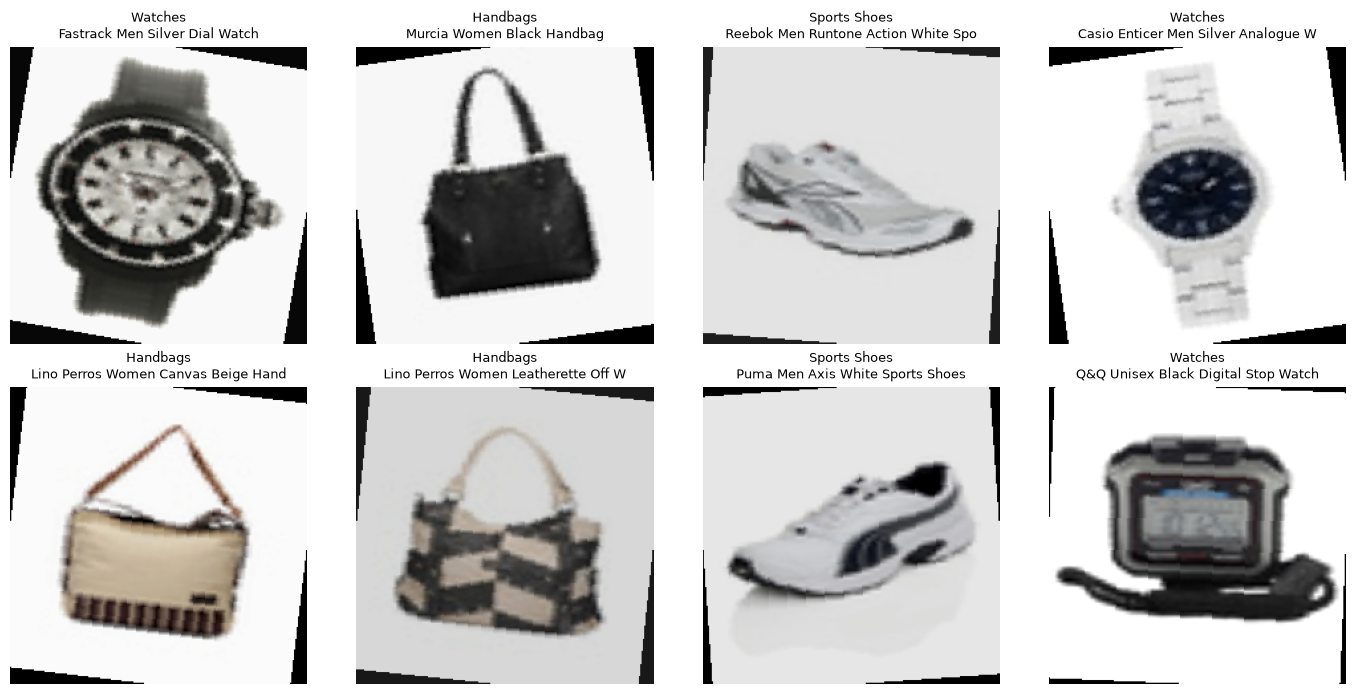

In [15]:
idx_to_class = dict(zip(class_to_idx['label'], class_to_idx['class_name']))
batch_size_to_show = min(8, len(train_batch['image']))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for axis, image_tensor, label, product_name in zip(
    axes.flat,
    train_batch['image'][:batch_size_to_show],
    train_batch['label'][:batch_size_to_show],
    train_batch['product_name'][:batch_size_to_show],
):
    axis.imshow(denormalize(image_tensor).permute(1, 2, 0))
    axis.set_title(f"{idx_to_class[int(label)]}\n{product_name[:35]}", fontsize=9)
    axis.axis('off')
plt.tight_layout()
plt.show()

## Этап 6. Финальный инженерный вывод

Подготовлен воспроизводимый пайплайн из шести частей: аудит метаданных и файлов, преобразование изображений, обработка названий товаров, собственный `ProductDataset`, создание `DataLoader` и проверка итогового батча. На каждом этапе проверяется согласованность данных между таблицей, изображениями и метками классов.

Для train используются случайные аугментации: горизонтальный переворот, небольшое вращение и изменение цвета. Для validation и test применяются только детерминированные преобразования. Это позволяет увеличить разнообразие обучающей выборки и при этом корректно сравнивать результаты на отложенных данных. Изображения приводятся к размеру 224×224 и нормализуются по статистикам ImageNet.

Текст очищается, токенизируется и кодируется словарём размером 764 токена, построенным только по train. Для обработки неизвестных слов используются `<UNK>`, для выравнивания длины последовательностей — `<PAD>`, максимальная длина названия составляет 16 токенов. Утечки информации из validation и test при построении словаря нет.

Итоговый `DataLoader` возвращает изображение размера `(32, 3, 224, 224)`, текст размера `(32, 16)` и вектор меток размера `(32,)`; все проверки батча пройдены. Следовательно, связка «изображение + название товара + числовая метка» готова для обучения классификатора. Следующим этапом целесообразно сравнить image-only и мультимодальную модели, отдельно проверить качество по каждому классу и оценить влияние небольшого исходного разрешения изображений и текстовых подсказок на результат.

In [18]:
print('Чек-лист пайплайна:')
checklist = {
    'metadata загружена': len(metadata) > 0,
    'class_name и label согласованы': label_consistent,
    'все изображения существуют': len(missing_paths) == 0,
    'изображения открываются': len(broken_images) == 0,
    'тексты не пустые': metadata['text_length'].gt(0).all(),
    'словарь построен по train': len(vocabulary) > len(SPECIAL_TOKENS),
    'Dataset возвращает корректный пример': sample_item['image'].shape == (3, IMAGE_SIZE, IMAGE_SIZE),
    'DataLoader возвращает корректный батч': train_batch['label'].ndim == 1,
}
for name, passed in checklist.items():
    print(f"{'[yes]' if passed else '[no]'} {name}")
print(f"Итог: {'пайплайн готов к обучению модели' if all(checklist.values()) else 'нужно исправить пункты чек-листа'}")

Чек-лист пайплайна:
[yes] metadata загружена
[yes] class_name и label согласованы
[yes] все изображения существуют
[yes] изображения открываются
[yes] тексты не пустые
[yes] словарь построен по train
[yes] Dataset возвращает корректный пример
[yes] DataLoader возвращает корректный батч
Итог: пайплайн готов к обучению модели
